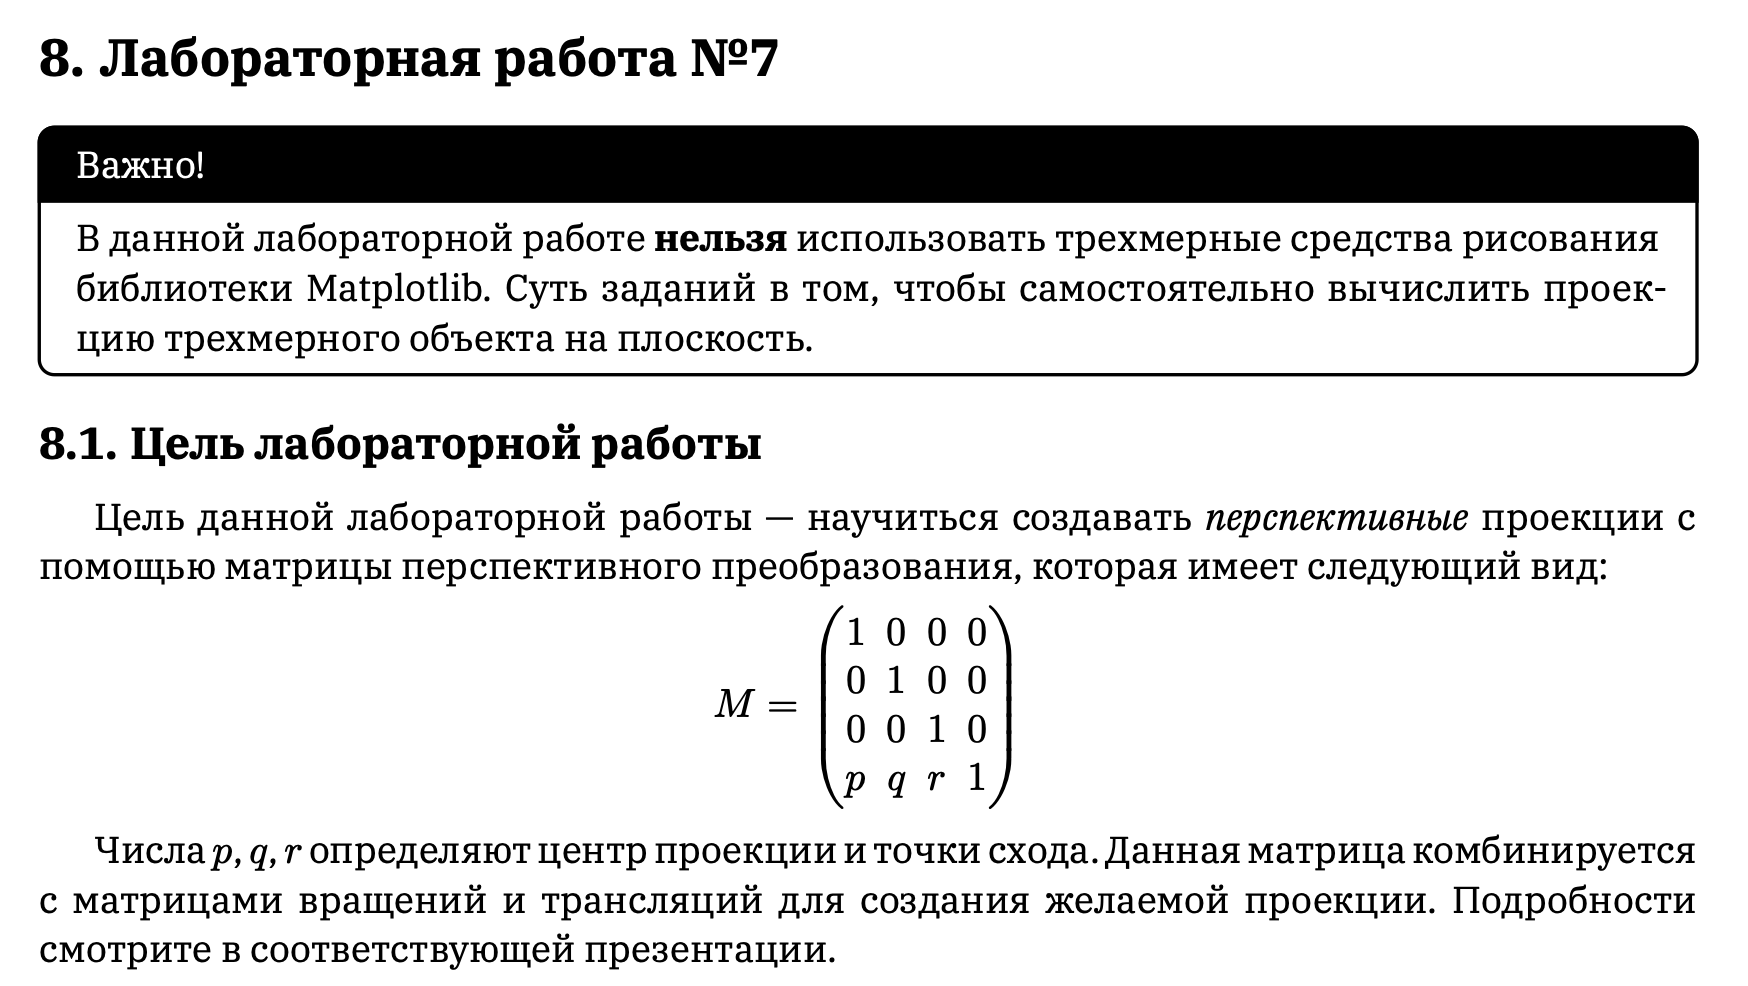

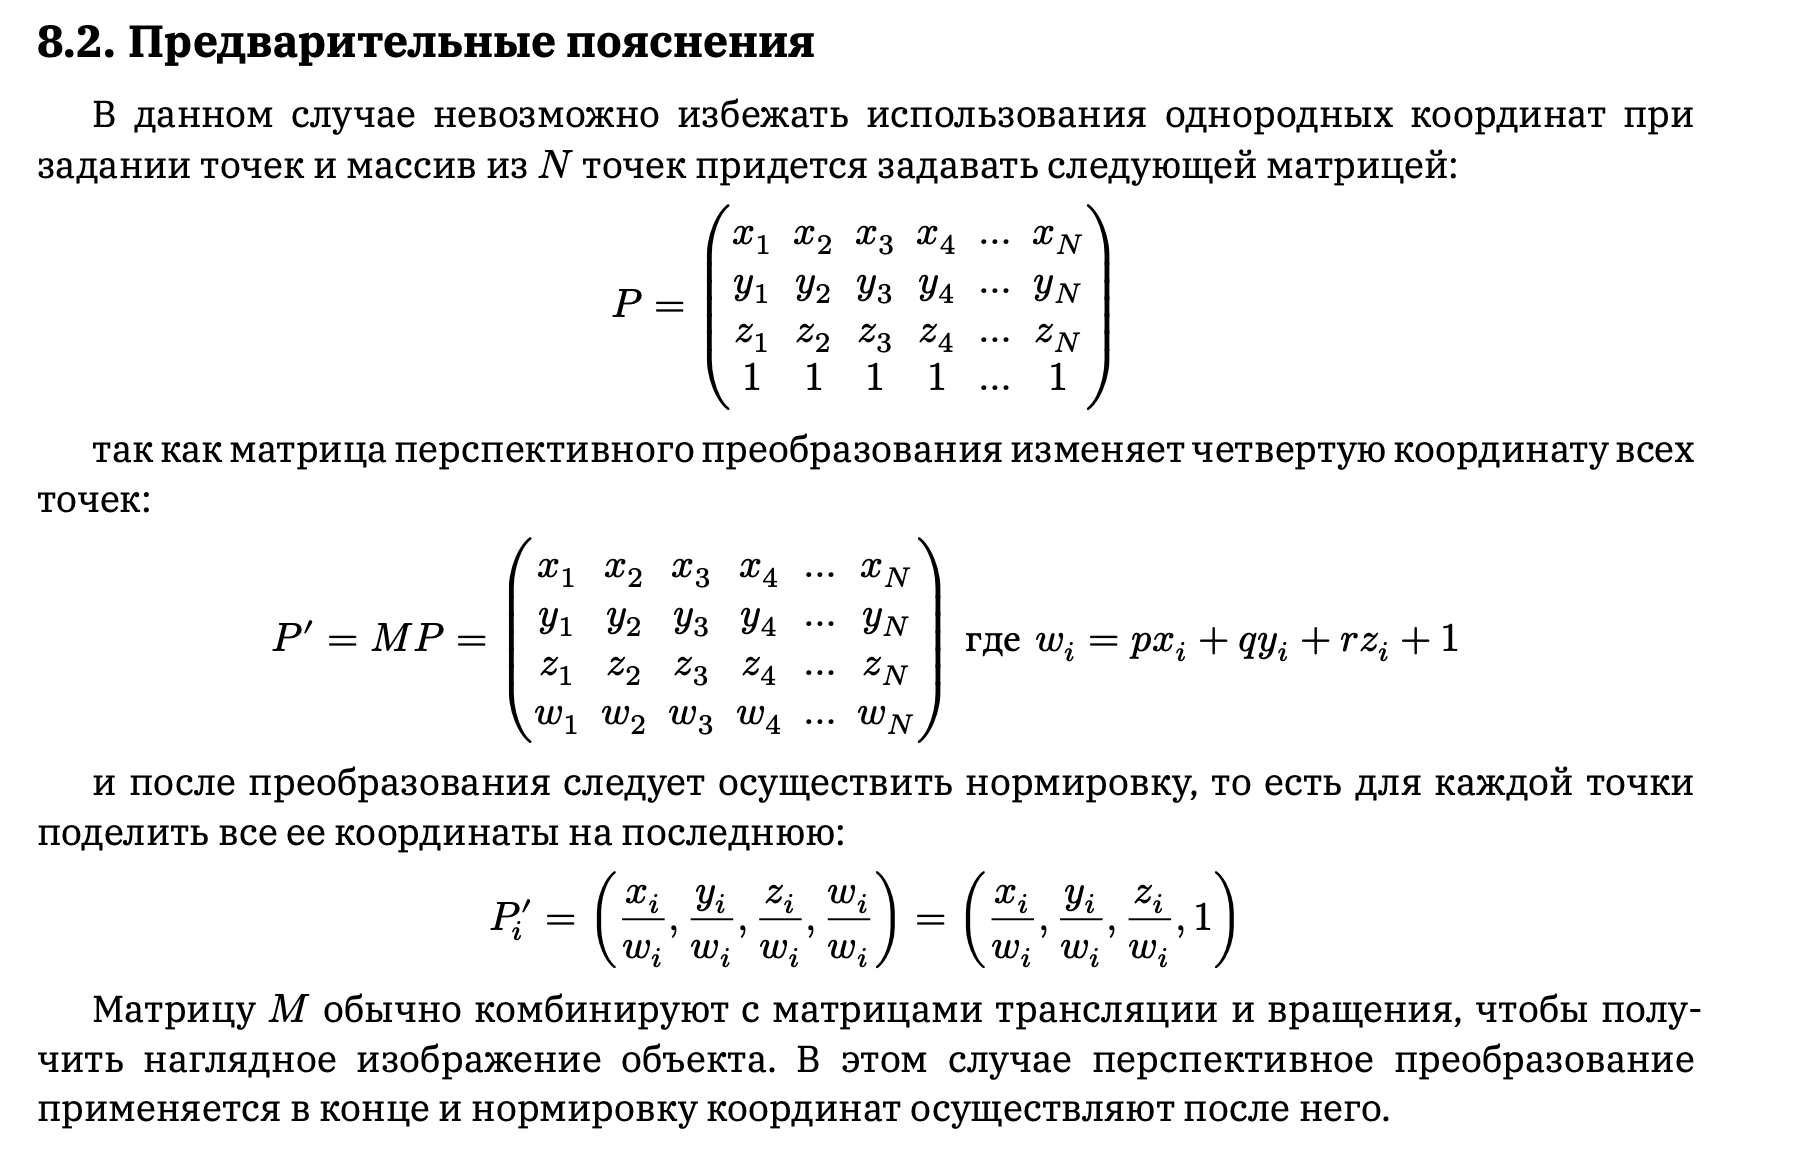

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from ipywidgets import interact, FloatSlider

# 1. Вершины куба (единичный куб, центр в (0,0,0))
cube_vertices = np.array([
    [0, 0, 0],  # 0
    [1, 0, 0],  # 1
    [1, 1, 0],  # 2
    [0, 1, 0],  # 3
    [0, 0, 1],  # 4
    [1, 0, 1],  # 5
    [1, 1, 1],  # 6
    [0, 1, 1],  # 7
])

# Рёбра куба (по парам индексов вершин)
cube_edges = [
    (0,1), (1,2), (2,3), (3,0),  # основание
    (4,5), (5,6), (6,7), (7,4),  # верх
    (0,4), (1,5), (2,6), (3,7)   # боковые
]

# Грани (для видимости)
cube_faces = [
    [0,1,2,3], [4,5,6,7], [0,1,5,4],
    [1,2,6,5], [2,3,7,6], [3,0,4,7]
]

# 2. Матрица перспективной проекции
def perspective_projection_matrix(p=0, q=0, r=-0.25):
    # p, q, r — параметры матрицы
    # x' = x / (1 + p*x + q*y + r*z)
    # y' = y / (1 + p*x + q*y + r*z)
    # (по сути, это частный случай проективной матрицы)
    def project(points):
        denom = 1 + p*points[:,0] + q*points[:,1] + r*points[:,2]
        x_proj = points[:,0] / denom
        y_proj = points[:,1] / denom
        return np.column_stack([x_proj, y_proj])
    return project

# 3. Вращение вокруг произвольной оси через точку P
def rotation_matrix(axis, theta_deg):
    theta = np.radians(theta_deg)
    axis = np.array(axis, dtype=float)
    axis = axis / np.linalg.norm(axis)
    x, y, z = axis
    c = np.cos(theta)
    s = np.sin(theta)
    C = 1 - c
    R = np.array([
        [c + x*x*C, x*y*C - z*s, x*z*C + y*s],
        [y*x*C + z*s, c + y*y*C, y*z*C - x*s],
        [z*x*C - y*s, z*y*C + x*s, c + z*z*C]
    ])
    return R

def rotate_around_axis(points, axis, theta_deg, point):
    # Переносим в начало, вращаем, возвращаем обратно
    shifted = points - point
    R = rotation_matrix(axis, theta_deg)
    rotated = shifted @ R.T
    return rotated + point

# 4. Визуализация
def plot_perspective_cube(
    p=0.0, q=0.0, r=-0.25,
    tx=0.0, ty=0.0, tz=0.0,
    ax1=1.0, ay1=0.0, az1=0.0,  # ось вращения
    theta=0.0,                  # угол вращения
    px=0.5, py=0.5, pz=0.5      # точка вращения (по умолчанию центр куба)
):
    # 1. Вращаем
    axis = [ax1, ay1, az1]
    point = [px, py, pz]
    cube_rot = rotate_around_axis(cube_vertices, axis, theta, point)
    # 2. Трансляция
    cube_trans = cube_rot + np.array([tx, ty, tz])
    # 3. Проекция
    project = perspective_projection_matrix(p, q, r)
    proj = project(cube_trans)
    # 4. Определяем видимость рёбер (по нормали к грани)
    face_normals = []
    for face in cube_faces:
        v0, v1, v2 = [cube_trans[i] for i in face[:3]]
        normal = np.cross(v1-v0, v2-v0)
        face_normals.append(normal)
    # Считаем, что наблюдатель смотрит из точки (0,0,∞) вдоль -z
    observer = np.array([0,0,10])
    visible_edges = set()
    for i, face in enumerate(cube_faces):
        center = np.mean([cube_trans[j] for j in face], axis=0)
        to_observer = observer - center
        if np.dot(face_normals[i], to_observer) > 0:
            # Грань видимая, её рёбра — видимые
            for k in range(4):
                a, b = face[k], face[(k+1)%4]
                visible_edges.add(tuple(sorted((a,b))))
    # 5. Рисуем
    fig, ax = plt.subplots(figsize=(7,7))
    # Рёбра
    for a, b in cube_edges:
        pts = proj[[a,b]]
        color = 'black' if tuple(sorted((a,b))) in visible_edges else 'gray'
        linestyle = '-' if color == 'black' else '--'
        ax.plot(pts[:,0], pts[:,1], color=color, linewidth=2, linestyle=linestyle)
    # Вершины
    for i, (x, y) in enumerate(proj):
        ax.text(x, y, f'{i}', color='red', fontsize=12)
    # 5. Прямые, продолжающие рёбра (точки схода)
    # Для каждой оси куба (x, y, z) найдём прямые, проведём их далеко
    directions = [
        cube_trans[1] - cube_trans[0],  # x
        cube_trans[3] - cube_trans[0],  # y
        cube_trans[4] - cube_trans[0],  # z
    ]
    for d, color in zip(directions, ['r', 'g', 'b']):
        # Через центр куба
        center = np.mean(cube_trans, axis=0)
        line_pts = np.array([center - 10*d, center + 10*d])
        proj_line = project(line_pts)
        ax.plot(proj_line[:,0], proj_line[:,1], color=color, linestyle=':', linewidth=1)
    ax.set_aspect('equal')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_title(f"Перспективная проекция куба (p={p}, q={q}, r={r}, θ={theta}°)")
    ax.grid(True)
    plt.show()

# 6. Интерактивные ползунки для параметров
interact(
    plot_perspective_cube,
    p=FloatSlider(value=0.0, min=-1.0, max=1.0, step=0.01, description='p'),
    q=FloatSlider(value=0.0, min=-1.0, max=1.0, step=0.01, description='q'),
    r=FloatSlider(value=-0.25, min=-1.0, max=1.0, step=0.01, description='r'),
    tx=FloatSlider(value=0.0, min=-2.0, max=2.0, step=0.1, description='tx'),
    ty=FloatSlider(value=0.0, min=-2.0, max=2.0, step=0.1, description='ty'),
    tz=FloatSlider(value=0.0, min=-2.0, max=2.0, step=0.1, description='tz'),
    ax1=FloatSlider(value=1.0, min=-1.0, max=1.0, step=0.1, description='ax'),
    ay1=FloatSlider(value=0.0, min=-1.0, max=1.0, step=0.1, description='ay'),
    az1=FloatSlider(value=0.0, min=-1.0, max=1.0, step=0.1, description='az'),
    theta=FloatSlider(value=0.0, min=0.0, max=360.0, step=1.0, description='θ (°)'),
    px=FloatSlider(value=0.5, min=0.0, max=1.0, step=0.01, description='Px'),
    py=FloatSlider(value=0.5, min=0.0, max=1.0, step=0.01, description='Py'),
    pz=FloatSlider(value=0.5, min=0.0, max=1.0, step=0.01, description='Pz'),
)

interactive(children=(FloatSlider(value=0.0, description='p', max=1.0, min=-1.0, step=0.01), FloatSlider(value…

<function __main__.plot_perspective_cube(p=0.0, q=0.0, r=-0.25, tx=0.0, ty=0.0, tz=0.0, ax1=1.0, ay1=0.0, az1=0.0, theta=0.0, px=0.5, py=0.5, pz=0.5)>

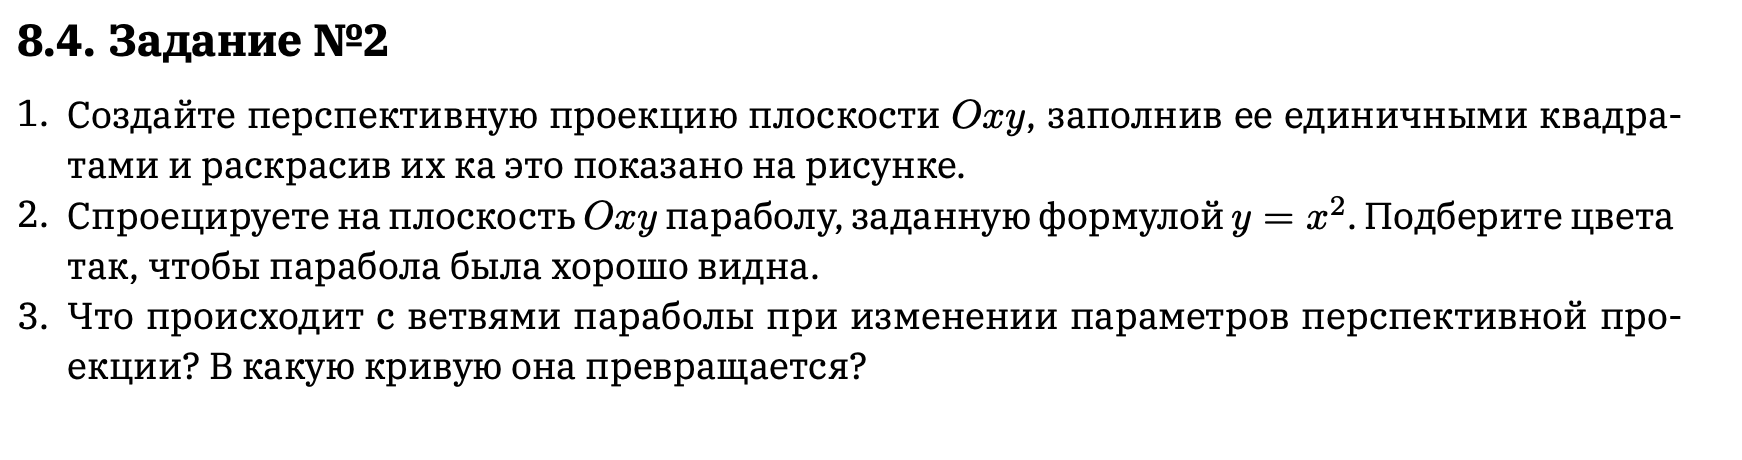

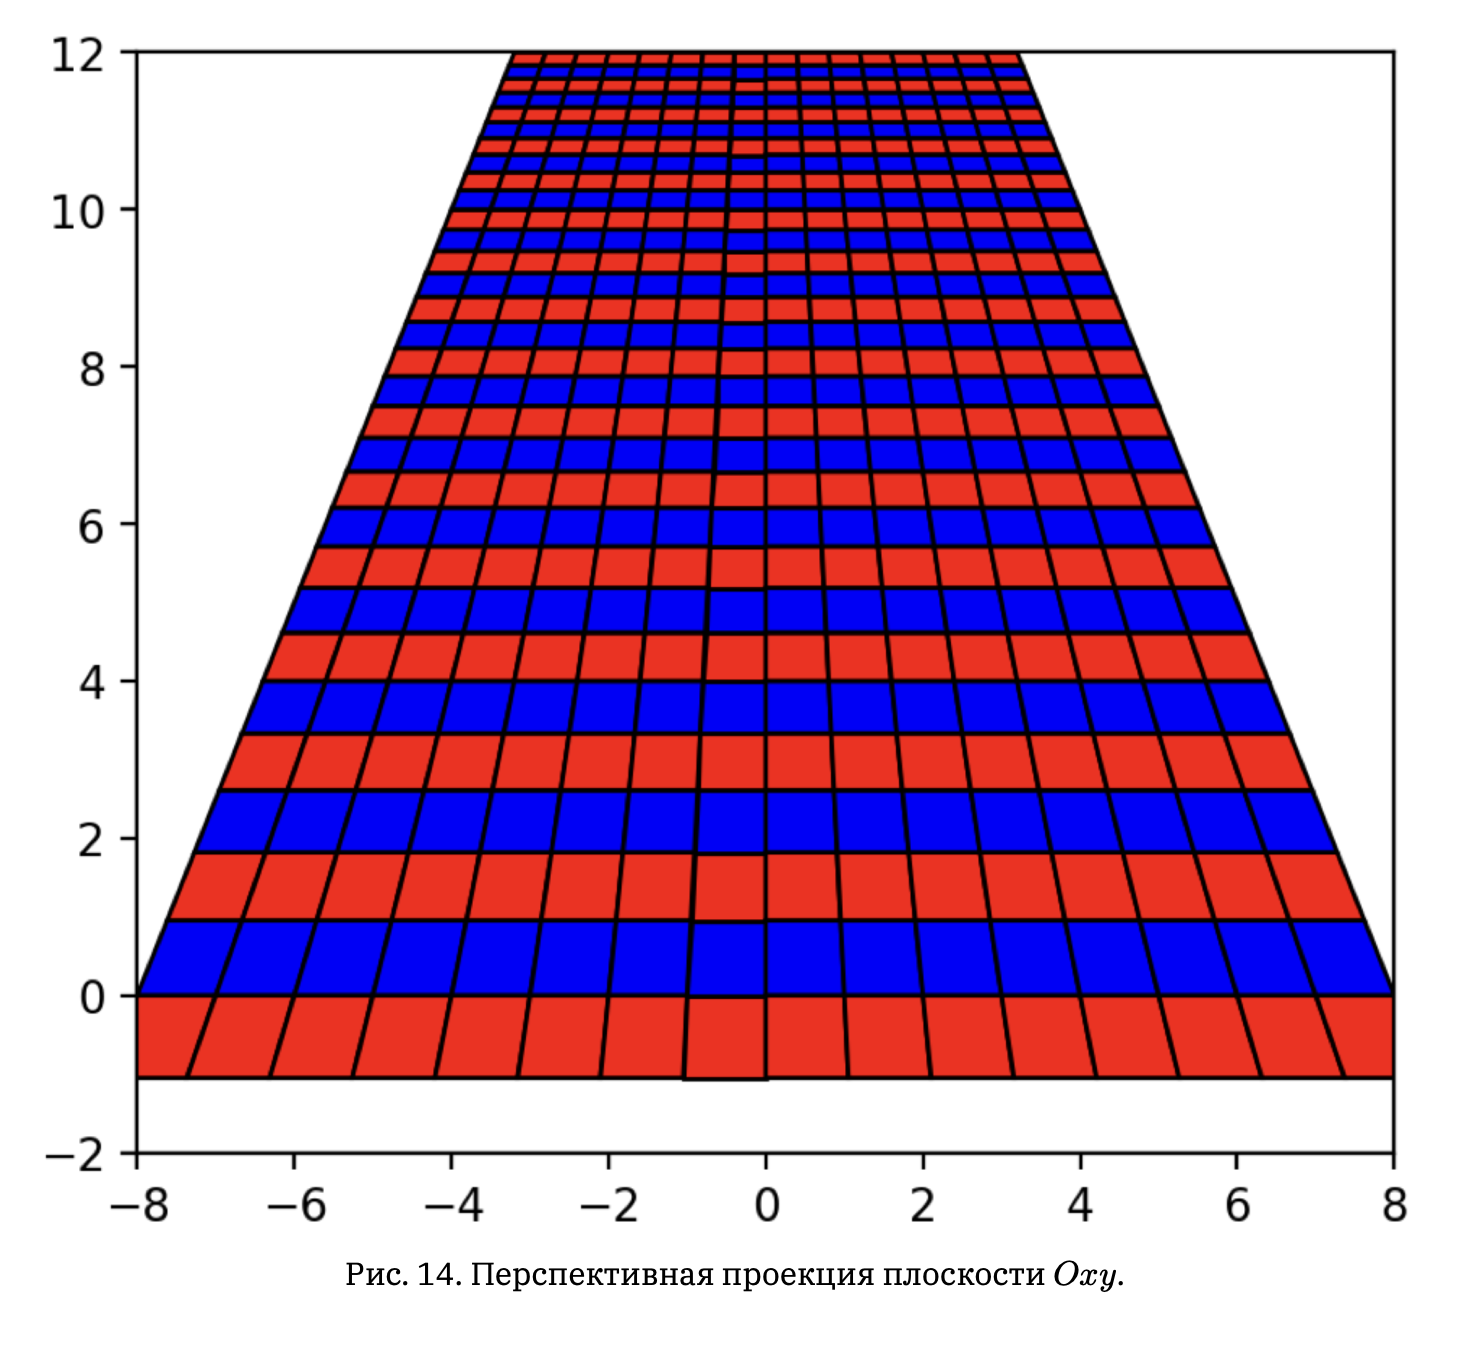

In [4]:
from ipywidgets import IntSlider

# 1. Перспективная проекция (как в предыдущем задании)
def perspective_projection_matrix(p=0, q=0, r=-0.25):
    def project(points):
        denom = 1 + p*points[:,0] + q*points[:,1] + r*points[:,2]
        x_proj = points[:,0] / denom
        y_proj = points[:,1] / denom
        return np.column_stack([x_proj, y_proj])
    return project

# 2. Визуализация
def plot_perspective_plane_and_parabola(p=0.0, q=0.0, r=-0.25, n=10, xlim=5):
    project = perspective_projection_matrix(p, q, r)
    fig, ax = plt.subplots(figsize=(8,8))
    # 1. Шахматное поле на плоскости Oxy (z=0)
    for i in range(-n, n):
        for j in range(-n, n):
            square = np.array([
                [i, j, 0],
                [i+1, j, 0],
                [i+1, j+1, 0],
                [i, j+1, 0]
            ])
            color = 'white' if (i+j)%2==0 else 'gray'
            sq_proj = project(square)
            ax.add_patch(Polygon(sq_proj, closed=True, facecolor=color, edgecolor='black', alpha=0.7))
    # 2. Парабола y = x^2 (z=0)
    x = np.linspace(-xlim, xlim, 400)
    y = x**2
    parabola = np.column_stack([x, y, np.zeros_like(x)])
    parabola_proj = project(parabola)
    ax.plot(parabola_proj[:,0], parabola_proj[:,1], color='crimson', linewidth=3, label=r'$y=x^2$')
    # 3. Оси
    origin = np.array([[0,0,0],[1,0,0],[0,1,0]])
    origin_proj = project(origin)
    ax.arrow(origin_proj[0,0], origin_proj[0,1], origin_proj[1,0]-origin_proj[0,0], origin_proj[1,1]-origin_proj[0,1], 
             head_width=0.2, head_length=0.3, fc='r', ec='r', linewidth=2)
    ax.arrow(origin_proj[0,0], origin_proj[0,1], origin_proj[2,0]-origin_proj[0,0], origin_proj[2,1]-origin_proj[0,1], 
             head_width=0.2, head_length=0.3, fc='g', ec='g', linewidth=2)
    ax.text(origin_proj[1,0], origin_proj[1,1], 'x', color='r', fontsize=14)
    ax.text(origin_proj[2,0], origin_proj[2,1], 'y', color='g', fontsize=14)
    ax.set_aspect('equal')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_title(f"Перспективная проекция плоскости Oxy и параболы $y=x^2$\n(p={p}, q={q}, r={r})")
    ax.legend()
    plt.grid(True)
    plt.show()

# 4. Интерактивные ползунки
interact(
    plot_perspective_plane_and_parabola,
    p=FloatSlider(value=0.0, min=-1.0, max=1.0, step=0.01, description='p'),
    q=FloatSlider(value=0.0, min=-1.0, max=1.0, step=0.01, description='q'),
    r=FloatSlider(value=-0.25, min=-1.0, max=1.0, step=0.01, description='r'),
    n=IntSlider(value=10, min=5, max=20, step=1, description='Размер поля'),
    xlim=FloatSlider(value=5, min=2, max=10, step=0.1, description='xlim')
)

interactive(children=(FloatSlider(value=0.0, description='p', max=1.0, min=-1.0, step=0.01), FloatSlider(value…

<function __main__.plot_perspective_plane_and_parabola(p=0.0, q=0.0, r=-0.25, n=10, xlim=5)>